# Experiment 3 — Scaling and controls
Run **270 primary models**: three input conditions × three training conditions
× six scales × five seeds. An additional 15 unit scale reference models provide
trajectory checks; they are not counted as primary runs.

| Training condition | Initial complex weights | Complex gradient after backward |
|---|---|---|
| Ordinary | Reference weights | Unchanged |
| Inverse initialization | Reference weights / alpha | Unchanged |
| Compensated SGD | Reference weights / alpha | Divide by alpha² |

Simple and nuisance coordinates are never scaled or compensated. C2 has its
**own** unit scale reference: it need not match C0's reference function.

In [1]:
from pathlib import Path
import sys, json, inspect
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

# Works when Jupyter starts inside experiment_3 or its parent project folder.
ROOT = Path.cwd()
if not (ROOT / 'experiment.py').exists():
    ROOT = ROOT / 'experiment_3'
assert (ROOT / 'experiment.py').exists(), 'Start Jupyter in experiment_3 or its parent folder.'
sys.path.insert(0, str(ROOT))
from experiment import (DATASETS, CONDITIONS, ALPHAS, SEEDS, make_splits, input_data,
    make_model, make_base, complex_columns, initial_checks, classification_metrics,
    conflict_metrics, counterfactual_metrics, train_model, compare_snapshots,
    settings, save_splits, save_json, save_rows, baseline_data, make_baseline,
    INITIAL_TOLERANCE, TRAJECTORY_TOLERANCE)

# Small matrix operations are usually faster with one CPU thread here.
torch.set_num_threads(1)
splits = make_splits()
print('Experiment folder:', ROOT)
print('PyTorch:', torch.__version__)

Experiment folder: c:\Users\ESHAAN\HAKUR\SimpBias\experiment_3
PyTorch: 2.14.1+cpu


In [2]:
QUICK_RUN = False  # True: 18 primary models, one seed, scales 1/5, 25 updates.
SHOW_LIVE = True
config = settings(QUICK_RUN)
RESULTS = ROOT / 'results' / 'preview' if QUICK_RUN else ROOT / 'results'
print(config)
print('Primary runs:', len(DATASETS)*len(CONDITIONS)*len(config['alphas'])*len(config['seeds']))

{'seeds': [42, 43, 44, 45, 46], 'alphas': [0.1, 0.5, 1.0, 2.0, 5.0, 10.0], 'steps': 500, 'lr': 0.03, 'quick': False}
Primary runs: 270


## 1 Review column selection and updates
C0 complex columns use slice 1:3; C1/C2 use 2:4. After each backward pass,
compensation divides only those gradient columns by alpha² before opt.step().
The loss and forward model are unchanged from continuous XNOR.

In [4]:
def show_training(key, history):
    if not SHOW_LIVE or (history[-1]['step'] % 100 and history[-1]['step'] != config['steps']):
        return
    frame = pd.DataFrame(history)
    clear_output(wait=True)
    has_conflicts = 'complex_conflict_agreement' in frame
    fig, axes = plt.subplots(1, 3 if has_conflicts else 2, figsize=(13, 3.3))
    for split in ['train', 'validation']:
        axes[0].plot(frame.step, frame[f'{split}_loss'], label=split)
        axes[1].plot(frame.step, frame[f'{split}_accuracy'], label=split)
    axes[0].set(title='BCE loss', xlabel='Update')
    axes[1].set(title='Accuracy', xlabel='Update', ylim=(-0.05, 1.05))
    if has_conflicts:
        axes[2].plot(frame.step, frame.complex_conflict_agreement)
        axes[2].set(title='Complex conflict agreement', xlabel='Update', ylim=(-0.05, 1.05))
    for ax in axes:
        ax.grid(alpha=0.2)
    axes[0].legend(); axes[1].legend()
    title = ' | '.join(f'{k}: {v}' for k, v in key.items() if k != 'run_id')
    fig.suptitle(title + f" | step {history[-1]['step']}/{config['steps']}")
    fig.tight_layout(); display(fig); plt.close(fig)

## 2 Run the paired experiment
Each CSV snapshot is saved after every completed primary run. A failure stops
the cell and leaves metadata incomplete; analysis refuses incomplete studies.
Re-running replaces the selected output files. Preview output cannot overwrite full-study output.
Recorded measurements include step 0 and every 25 updates through step 500.

In [5]:
# These files belong only to this experiment. Preview uses a separate folder.
metadata = dict(config, status='running', datasets=DATASETS, conditions=CONDITIONS,
    expected_runs=len(DATASETS)*len(CONDITIONS)*len(config['alphas'])*len(config['seeds']),
    torch_version=torch.__version__, data_seeds={'train':11,'validation':12,'test':13,'conflicts':14},
    samples={name:len(data[0]) for name,data in splits.items()},
    initial_tolerance=INITIAL_TOLERANCE, trajectory_tolerance=TRAJECTORY_TOLERANCE)
save_json(RESULTS / 'metadata.json',metadata)
save_splits(RESULTS,splits)
rows, all_history, trajectory_checks = [], [], []

### Train the models
The loops below show every comparison directly. Change the settings above, not the controls inside the loop.

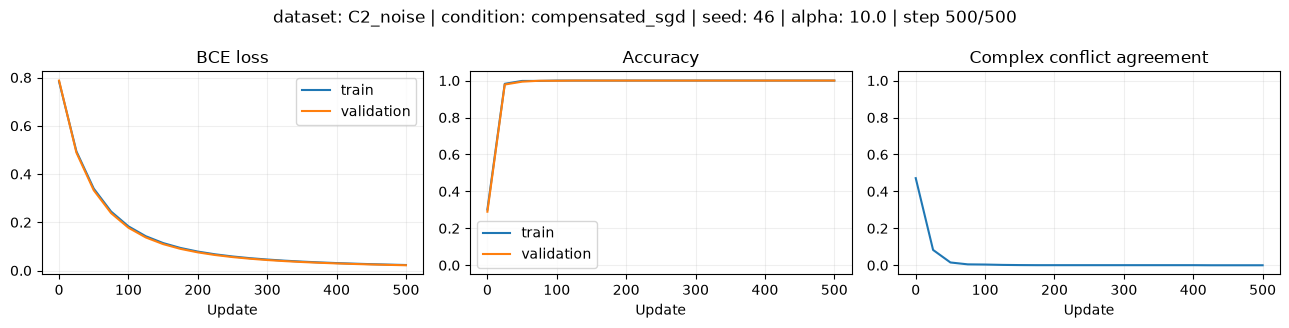

270/270: C2_noise, compensated_sgd, alpha 10, seed 46


test_accuracy  test_loss  \
dataset     condition       alpha                             
C0_original compensated_sgd 0.1              1.0   0.023972   
                            0.5              1.0   0.023972   
                            1.0              1.0   0.023972   
                            2.0              1.0   0.023972   
                            5.0              1.0   0.023972   
                            10.0             1.0   0.023972   
            inverse_init    0.1              1.0   0.027363   
                            0.5              1.0   0.026305   
                            1.0              1.0   0.023972   
                            2.0              1.0   0.018827   
                            5.0              1.0   0.008416   
                            10.0             1.0   0.003817   
            ordinary        0.1              1.0   0.023066   
                            0.5              1.0   0.024512   
                            1.0              1.0   0.023972   
                            2.0              1.0   0.015562   
                            5.0              1.0   0.005230   
                            10.0             1.0   0.001943   
C1_zero     compensated_sgd 0.1              1.0   0.023972   
                            0.5              1.0   0.023972   
                            1.0              1.0   0.023972   
                            2.0              1.0   0.023972   
                            5.0              1.0   0.023972   
                            10.0             1.0   0.023972   
            inverse_init    0.1              1.0   0.027363   
                            0.5              1.0   0.026305   
                            1.0              1.0   0.023972   
                            2.0              1.0   0.018827   
                            5.0              1.0   0.008416   
                            10.0             1.0   0.003817   
            ordinary        0.1              1.0   0.023066   
                            0.5              1.0   0.024512   
                            1.0              1.0   0.023972   
                            2.0              1.0   0.015562   
                            5.0              1.0   0.005230   
                            10.0             1.0   0.001943   
C2_noise    compensated_sgd 0.1              1.0   0.026009   
                            0.5              1.0   0.026009   
                            1.0              1.0   0.026009   
                            2.0              1.0   0.026009   
                            5.0              1.0   0.026009   
                            10.0             1.0   0.026009   
            inverse_init    0.1              1.0   0.029268   
                            0.5              1.0   0.028256   
                            1.0              1.0   0.026009   
                            2.0              1.0   0.020589   
                            5.0              1.0   0.008756   
                            10.0             1.0   0.003827   
            ordinary        0.1              1.0   0.025383   
                            0.5              1.0   0.026653   
                            1.0              1.0   0.026009   
                            2.0              1.0   0.016839   
                            5.0              1.0   0.005523   
                            10.0             1.0   0.002004   

                                   complex_conflict_agreement  
dataset     condition       alpha                              
C0_original compensated_sgd 0.1                      0.001074  
                            0.5                      0.001074  
                            1.0                      0.001074  
                            2.0                      0.001074  
                            5.0                      0.001074  
                            10.0                     0.001

In [6]:
for seed in config['seeds']:
    original_snapshots = {}
    for dataset in DATASETS:
        # Each input condition needs its OWN unit-scale reference trajectory.
        unit = {name:input_data(value,dataset) for name,value in splits.items()}
        _, reference = train_model(make_model(seed,dataset),unit['train'],unit['validation'],
            steps=config['steps'],lr=config['lr'],dataset=dataset,conflicts=unit['conflicts'])

        for condition in CONDITIONS:
            for alpha in config['alphas']:
                key = dict(dataset=dataset,condition=condition,seed=seed,alpha=alpha)
                data = {name:input_data(value,dataset,alpha) for name,value in splits.items()}
                model = make_model(seed,dataset,alpha,condition)
                initial = dict.fromkeys(['initial_preactivation_error','initial_logit_error','initial_gradient_scaling_error'], '')
                if condition != 'ordinary':
                    initial = initial_checks(make_model(seed,dataset),model,unit['train'],data['train'],dataset,alpha)
                    assert max(initial.values()) < INITIAL_TOLERANCE, initial

                callback = (lambda history: show_training(key,history)) if SHOW_LIVE else None
                history, snapshots = train_model(model,data['train'],data['validation'],
                    steps=config['steps'],lr=config['lr'],dataset=dataset,alpha=alpha,
                    condition=condition,conflicts=data['conflicts'],on_log=callback)
                row = dict(key, **initial, **history[-1])
                row.update({f'test_{k}':v for k,v in classification_metrics(model,data['test']).items()})
                row.update({f'test_{k}':v for k,v in counterfactual_metrics(model,data['test'][0]).items()})

                # Check compensation against the condition's unit-scale reference.
                if condition == 'compensated_sgd':
                    compared = compare_snapshots(snapshots,reference)
                    assert max(max(r['logit_error'],r['parameter_error']) for r in compared) < TRAJECTORY_TOLERANCE
                    trajectory_checks.extend(dict(key,check='compensated_vs_unit',**r) for r in compared)
                # Check zero padding against the corresponding three-input model.
                if dataset == 'C0_original':
                    original_snapshots[(condition,alpha)] = snapshots
                if dataset == 'C1_zero':
                    compared = compare_snapshots(snapshots,original_snapshots[(condition,alpha)],'shared_parameters')
                    assert max(max(r['logit_error'],r['parameter_error']) for r in compared) < TRAJECTORY_TOLERANCE
                    trajectory_checks.extend(dict(key,check='c1_vs_c0',**r) for r in compared)

                rows.append(row)
                all_history.extend(dict(key,**r) for r in history)
                save_rows(RESULTS / 'summary.csv',rows)
                save_rows(RESULTS / 'all_runs.csv',all_history)
                save_rows(RESULTS / 'trajectory_checks.csv',trajectory_checks)
                print(f"{len(rows)}/{metadata['expected_runs']}: {dataset}, {condition}, alpha {alpha:g}, seed {seed}")

# If an assertion or training step fails, this completion marker is never set.
metadata['status'] = 'complete'
save_json(RESULTS / 'metadata.json',metadata)
final = pd.DataFrame(rows)
display(final.groupby(['dataset','condition','alpha'])[['test_accuracy','test_loss','complex_conflict_agreement']].mean())

## 3 Verify numerical controls and inspect seed variation
The tolerance is 1e-6 for initial matching and 1e-4 for maximum absolute
trajectory discrepancies. Trajectory checks compare validation plus conflict
logits and effective parameters at every recorded checkpoint, not every update.
C0/C1 comparisons exclude the inactive nuisance weight column. The compensation
comparison includes it because the two models have the same input width.

In [7]:
display(final[['dataset','condition','alpha','seed','test_accuracy','complex_conflict_agreement']])
checks = pd.DataFrame(trajectory_checks)
display(checks.groupby(['dataset','check'])[['logit_error','parameter_error']].max())
print('Next: run Notebook 03 to compare all conditions and export graphs.')

,dataset,condition,alpha,seed,test_accuracy,complex_conflict_agreement
0,C0_original,ordinary,0.1,42,1.0,0.000000
1,C0_original,ordinary,0.5,42,1.0,0.000000
2,C0_original,ordinary,1.0,42,1.0,0.005371
3,C0_original,ordinary,2.0,42,1.0,0.800781
4,C0_original,ordinary,5.0,42,1.0,1.000000
...,...,...,...,...,...,...
265,C2_noise,compensated_sgd,0.5,46,1.0,0.000000
266,C2_noise,compensated_sgd,1.0,46,1.0,0.000000
267,C2_noise,compensated_sgd,2.0,46,1.0,0.000000
268,C2_noise,compensated_sgd,5.0,46,1.0,0.000000


logit_error  parameter_error
dataset     check                                            
C0_original compensated_vs_unit     0.000003         0.000002
C1_zero     c1_vs_c0                0.000000         0.000000
            compensated_vs_unit     0.000003         0.000002
C2_noise    compensated_vs_unit     0.000006         0.000002

Next: run Notebook 03 to compare all conditions and export graphs.
